In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (175341, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [3]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing = missing[missing["Missing Count"] > 0]

if missing.empty:
    print("No missing values found.")
else:
    display(missing)

No missing values found.


In [4]:
print("Total Records:", len(df))
print("Exact Duplicate Records:", df.duplicated().sum())

features = df.drop(
    columns=["id", "label", "attack_cat"],
    errors="ignore"
)

print("Duplicate Feature Records:",
      features.duplicated().sum())

Total Records: 175341
Exact Duplicate Records: 0
Duplicate Feature Records: 74301


In [5]:
class_counts = df["label"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_counts / len(df) * 100
})

class_summary = class_summary.rename(
    index={0: "Normal", 1: "Malicious"}
)

display(class_summary)

,Count,Percentage
label,,
Normal,56000,31.937767
Malicious,119341,68.062233


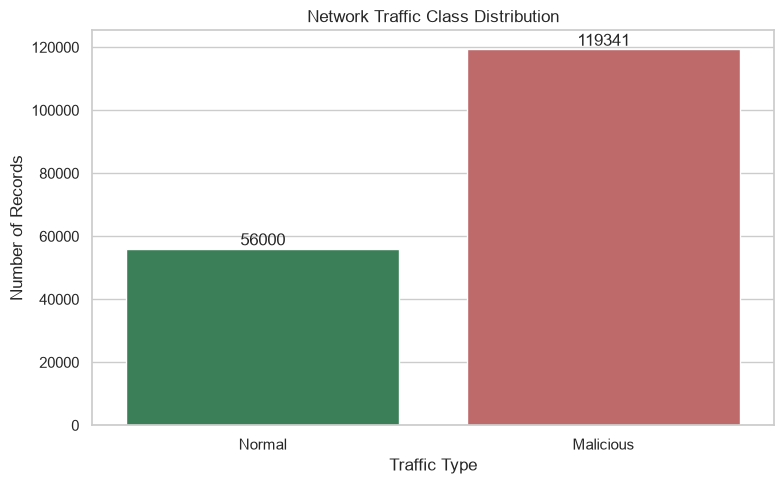

In [6]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette=["seagreen", "indianred"],
    legend=False
)

plt.xticks([0, 1], ["Normal", "Malicious"])

for container in ax.containers:
    ax.bar_label(container)

plt.title("Network Traffic Class Distribution")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "class_distribution.png", dpi=300)
plt.show()

In [7]:
attack_counts = df["attack_cat"].value_counts()

attack_summary = pd.DataFrame({
    "Count": attack_counts,
    "Percentage": attack_counts / len(df) * 100
})

display(attack_summary)

,Count,Percentage
attack_cat,,
Normal,56000,31.937767
Generic,40000,22.812691
Exploits,33393,19.044605
Fuzzers,18184,10.370649
DoS,12264,6.994371
Reconnaissance,10491,5.983198
Analysis,2000,1.140635
Backdoor,1746,0.995774
Shellcode,1133,0.646169


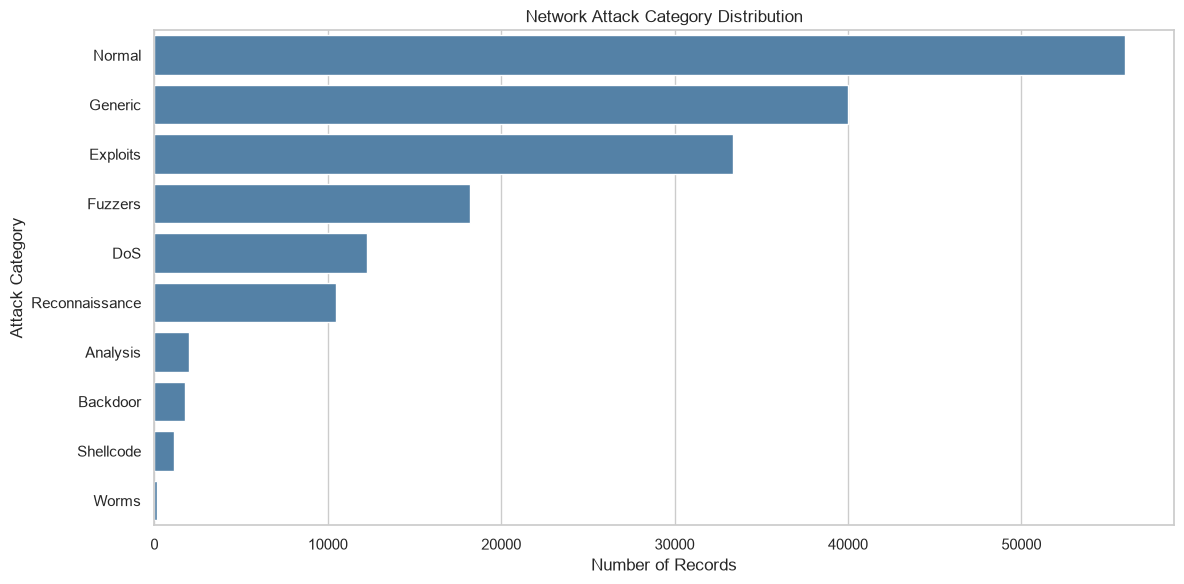

In [8]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="attack_cat",
    order=df["attack_cat"].value_counts().index,
    color="steelblue"
)

plt.title("Network Attack Category Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Attack Category")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "attack_distribution.png", dpi=300)
plt.show()

In [9]:
X = df.drop(columns=["id", "label", "attack_cat"])

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:", len(numerical_features))
print(numerical_features)

print("\nCategorical Features:", len(categorical_features))
print(categorical_features)

Numerical Features: 39
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']

Categorical Features: 3
['proto', 'service', 'state']


In [10]:
for column in categorical_features:
    print("\nFeature:", column)
    print("Unique Values:", df[column].nunique())
    print(df[column].value_counts().head(10))


Feature: proto
Unique Values: 133
proto
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
sctp       1150
any         300
gre         225
sun-nd      201
swipe       201
Name: count, dtype: int64

Feature: service
Unique Values: 13
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
Name: count, dtype: int64

Feature: state
Unique Values: 9
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64


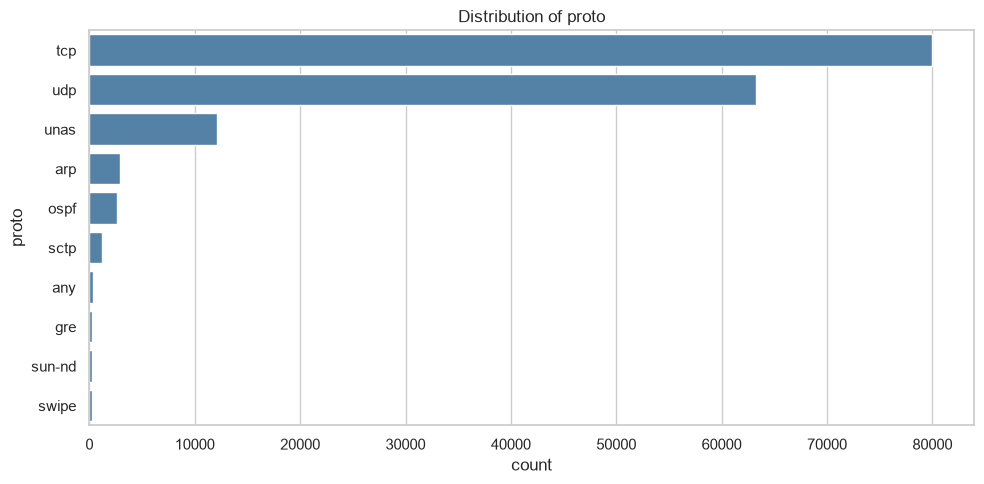

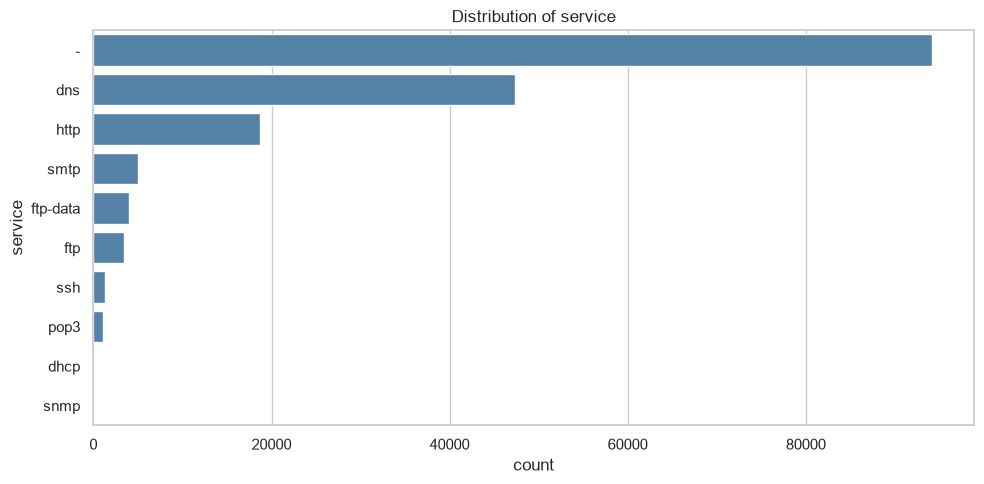

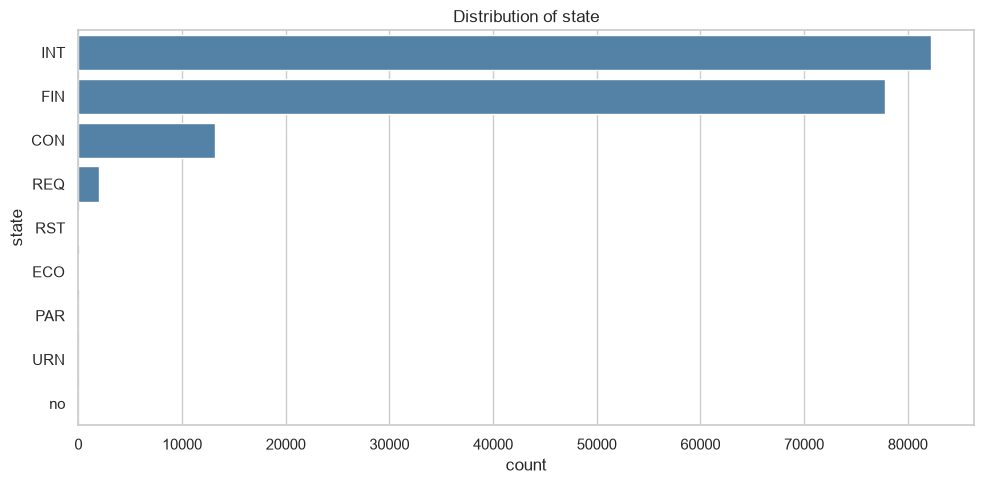

In [11]:
for column in categorical_features:

    plt.figure(figsize=(10, 5))

    order = df[column].value_counts().head(10).index

    sns.countplot(
        data=df,
        y=column,
        order=order,
        color="steelblue"
    )

    plt.title(f"Distribution of {column}")
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"{column}_distribution.png",
        dpi=300
    )

    plt.show()

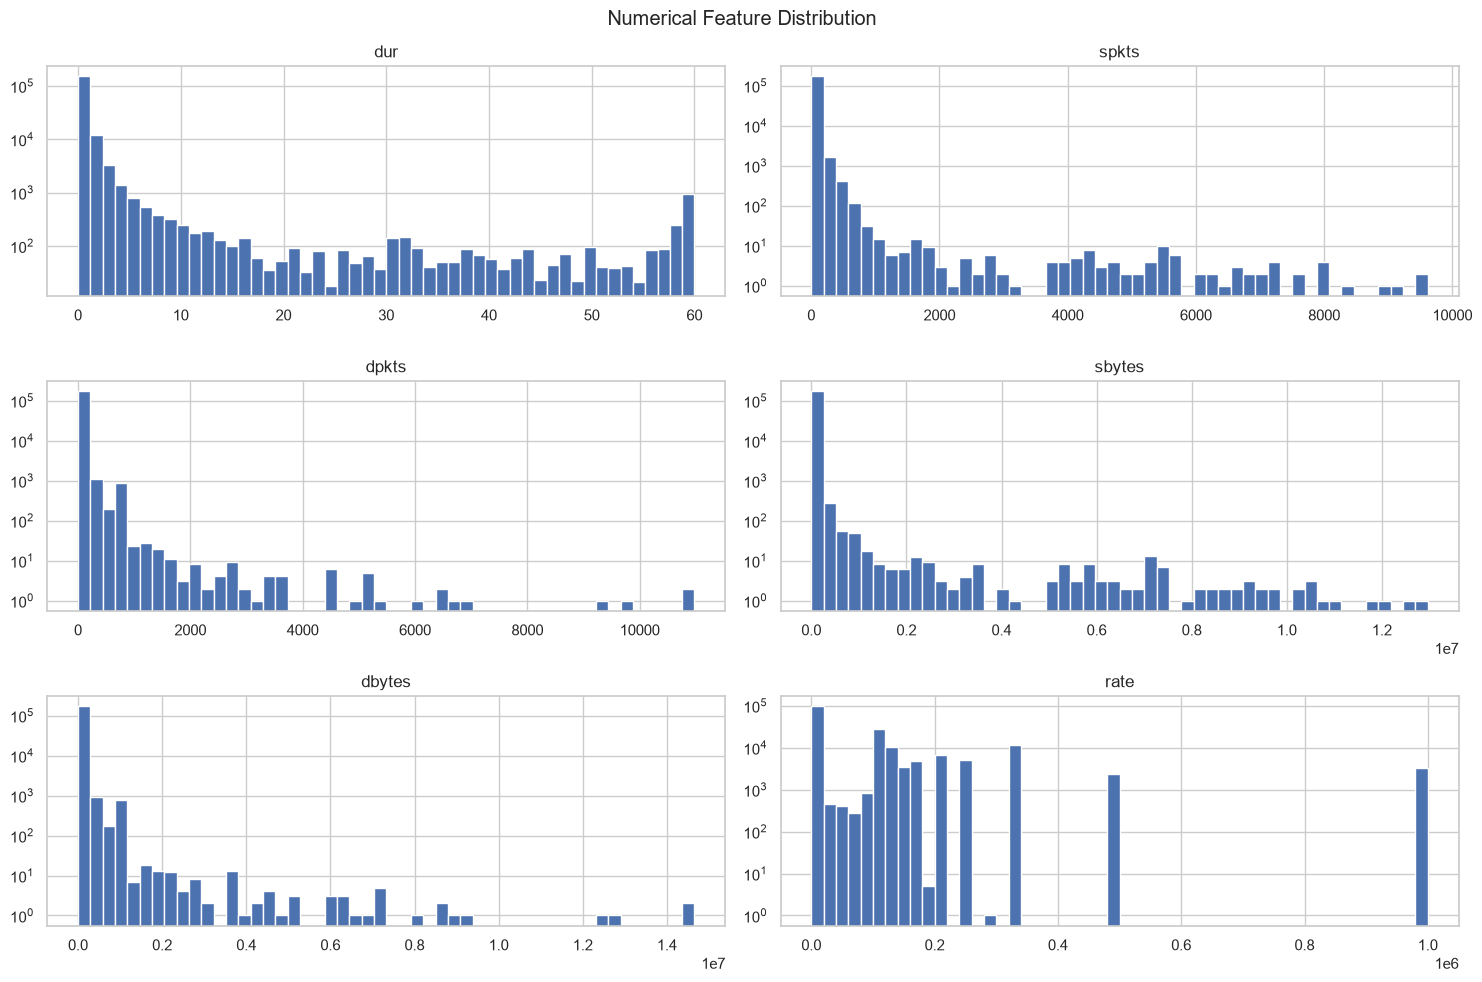

In [12]:
selected_features = [
    "dur",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate"
]

df[selected_features].hist(
    bins=50,
    figsize=(15, 10),
    log=True
)

plt.suptitle("Numerical Feature Distribution")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "numerical_distribution.png",
    dpi=300
)

plt.show()

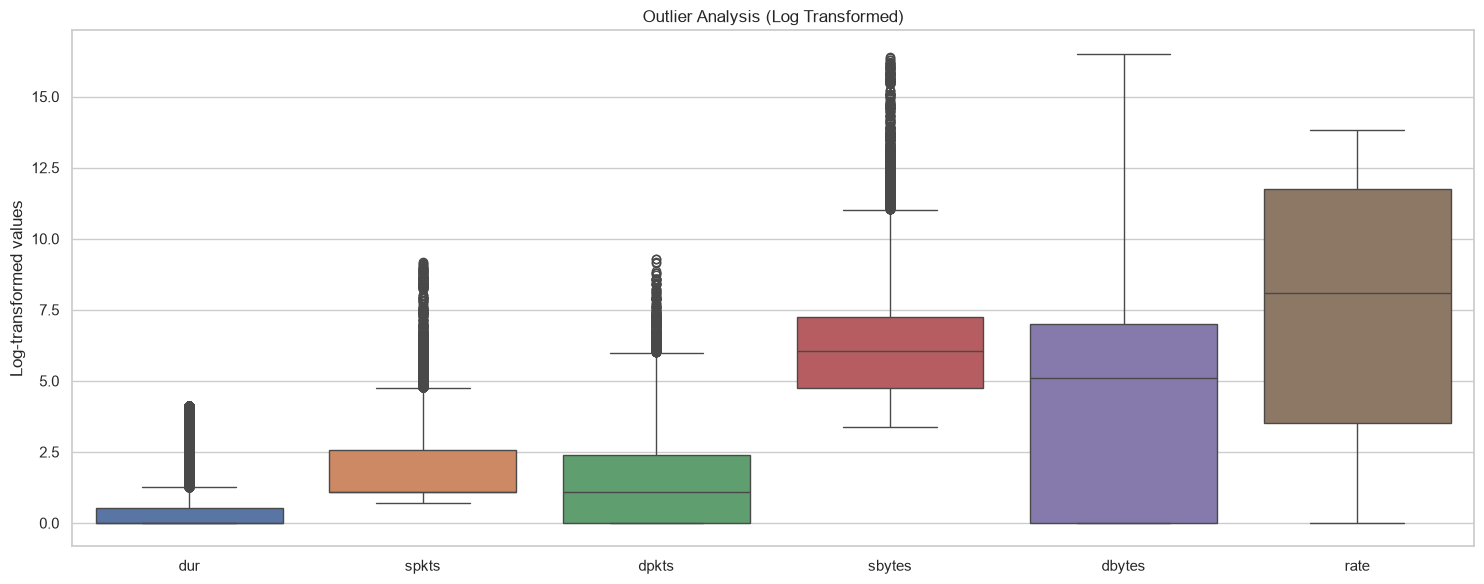

In [13]:
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=np.log1p(df[selected_features])
)

plt.title("Outlier Analysis (Log Transformed)")
plt.ylabel("Log-transformed values")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "outlier_analysis.png", dpi=300)
plt.show()

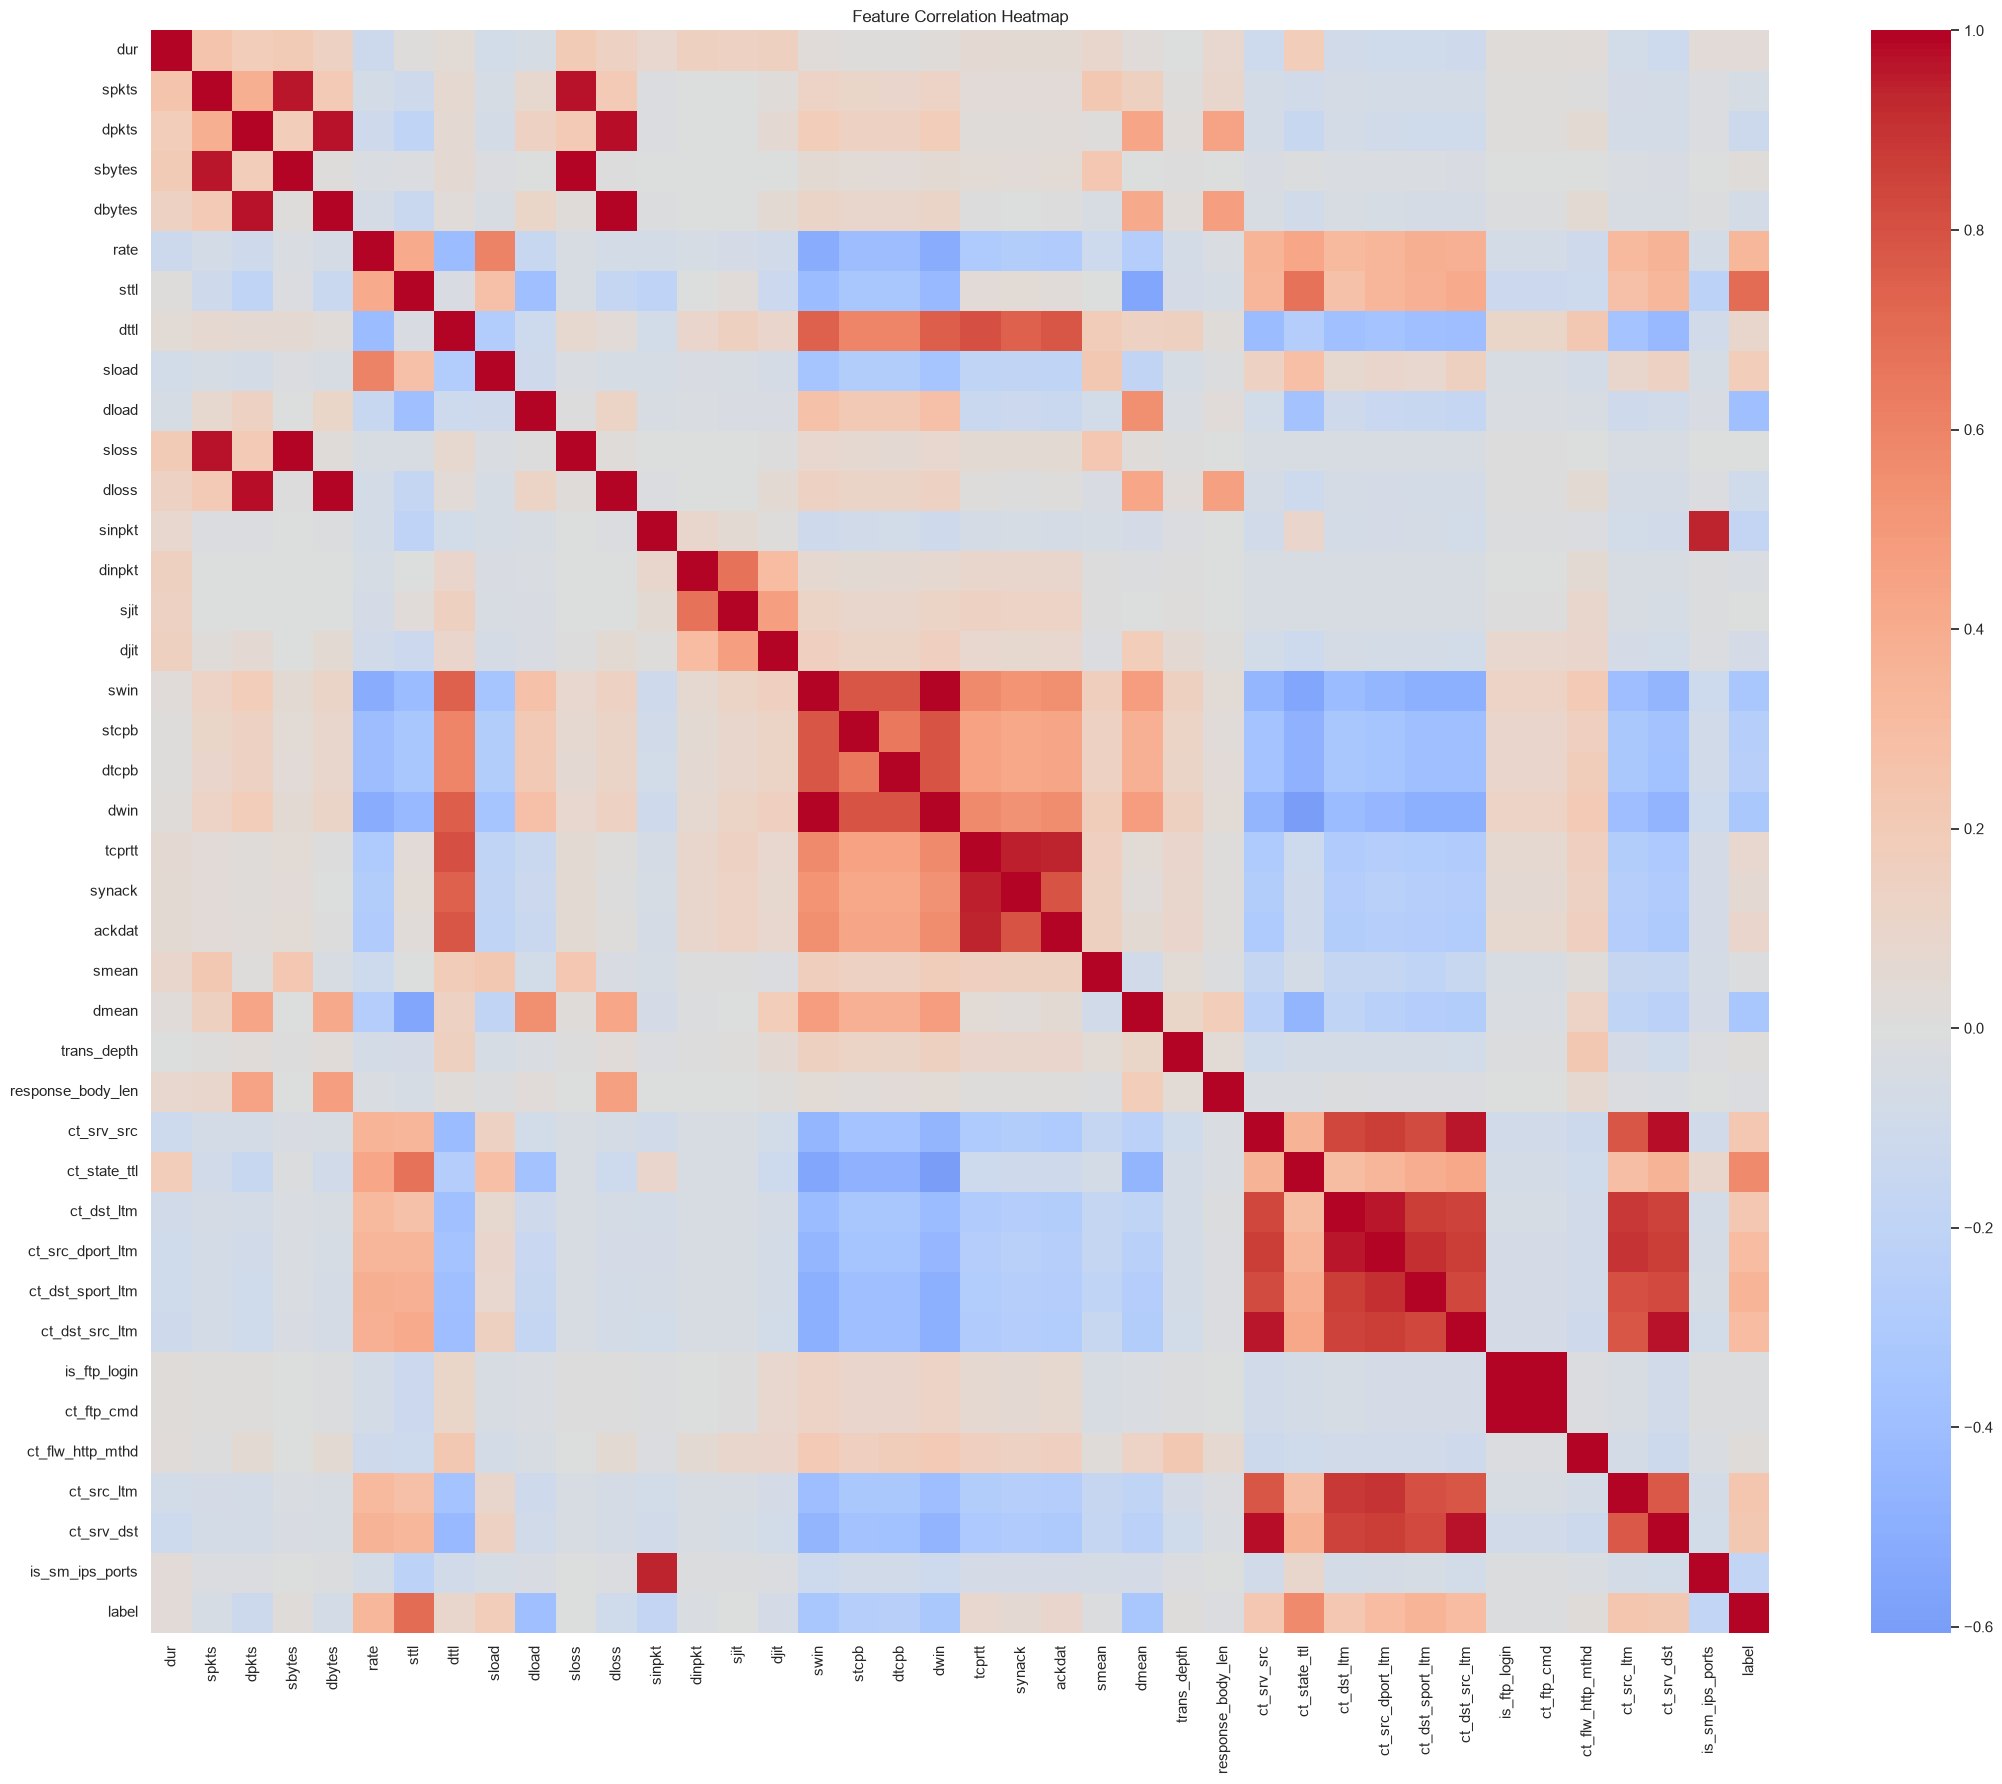

In [14]:
corr_data = df[numerical_features + ["label"]]

correlation = corr_data.corr()

plt.figure(figsize=(22, 18))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "correlation_heatmap.png", dpi=300)
plt.show()

Top 15 Features Correlated with Target:


sttl                0.692741
ct_state_ttl        0.577704
dload              -0.393739
ct_dst_sport_ltm    0.357213
dmean              -0.341806
rate                0.337979
swin               -0.333633
dwin               -0.319626
ct_src_dport_ltm    0.305579
ct_dst_src_ltm      0.303855
stcpb              -0.255006
dtcpb              -0.250340
ct_src_ltm          0.238225
ct_dst_ltm          0.229887
ct_srv_src          0.229044
Name: label, dtype: float64

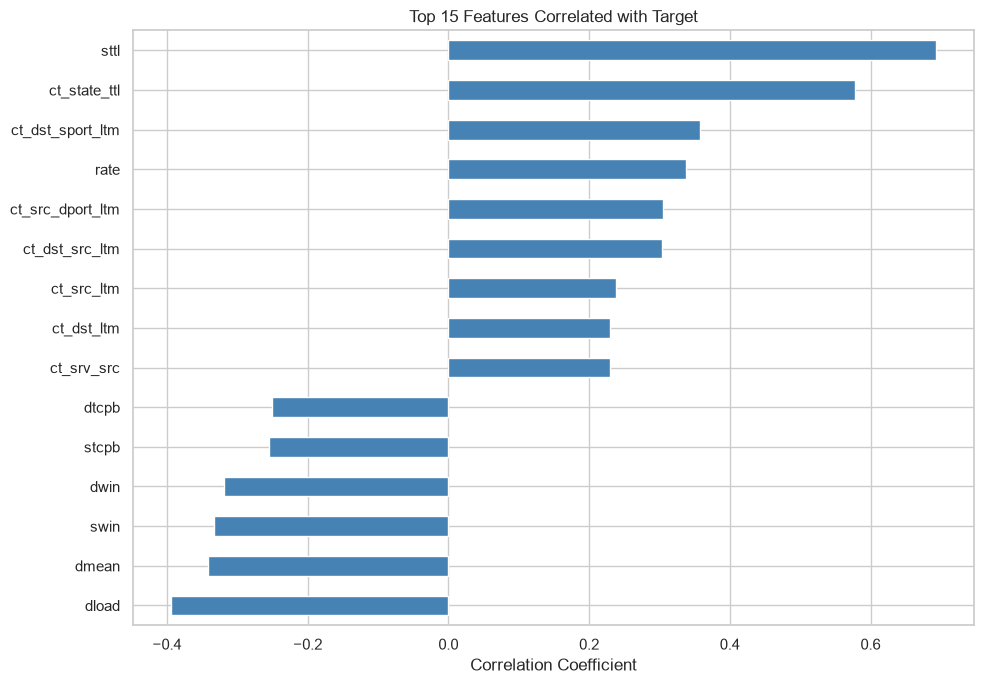

In [17]:
target_corr = correlation["label"].drop("label")

target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

print("Top 15 Features Correlated with Target:")

display(target_corr.head(15))


plt.figure(figsize=(10, 7))

target_corr.head(15).sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 15 Features Correlated with Target")
plt.xlabel("Correlation Coefficient")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "target_correlation.png", dpi=300)
plt.show()

In [18]:
RESULT_DIR = Path("../reports/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

class_summary.to_csv(
    RESULT_DIR / "class_distribution.csv"
)

attack_summary.to_csv(
    RESULT_DIR / "attack_distribution.csv"
)

target_corr.to_csv(
    RESULT_DIR / "feature_correlation.csv"
)

print("EDA reports saved successfully!")

EDA reports saved successfully!
